In [25]:
import pandas as pd
import numpy as np

In [44]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names) # type: ignore
y = pd.DataFrame(data.target, columns=['target']) # type: ignore

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
class my_linear:
    def __init__(self, input_size, output_size):
        self.W = np.random.randn(input_size, output_size) * 0.01
        self.b = np.zeros(output_size)

    def forward(self, x):
        self.x = x
        return np.dot(x, self.W) + self.b

    def backward(self, dL_ds, lr = 0.001):
        dL_db = np.mean(dL_ds, axis=0)
        dL_dw = np.dot(self.x.T, dL_ds)

        self.b -= dL_db * lr
        self.W -= dL_dw * lr

In [29]:
def softmax(logits):
    max_logits = np.max(logits, axis=1, keepdims=True)
    shifted_logits = logits - max_logits

    exp_logits = np.exp(shifted_logits)

    probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

    return probs

class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.y_true_one_hot = None

    def forward(self, logits, y_true):
        self.probs = softmax(logits)

        N = logits.shape[0]

        y_true = y_true.ravel() 

        self.y_true_one_hot = np.zeros_like(self.probs)
        self.y_true_one_hot[np.arange(N), y_true] = 1

        loss = -np.sum(self.y_true_one_hot * np.log(self.probs + 1e-15)) / N

        return loss

    def backward(self):
        N = self.probs.shape[0] # type: ignore
        return (self.probs - self.y_true_one_hot) / N # type: ignore

In [30]:
linear = my_linear(13, 3)
softmax_cross_entropy = SoftmaxCrossEntropy()

lr = 0.01

history = []

for epoch in range(100):
    logits = linear.forward(X_train)
    loss = softmax_cross_entropy.forward(logits, y_train.values)
    dL_ds = softmax_cross_entropy.backward()
    linear.backward(dL_ds, lr)

    history.append(loss)

    if epoch % 10 == 0:
        print(f'Epoch: {epoch}, Loss: {loss}')

Epoch: 0, Loss: 1.0971358322776843
Epoch: 10, Loss: 0.9406754971129734
Epoch: 20, Loss: 0.8199473021591983
Epoch: 30, Loss: 0.7262287817097196
Epoch: 40, Loss: 0.6524808996678526
Epoch: 50, Loss: 0.5934549494839172
Epoch: 60, Loss: 0.545375115855435
Epoch: 70, Loss: 0.505551954220665
Epoch: 80, Loss: 0.4720612217520048
Epoch: 90, Loss: 0.4435098334348887


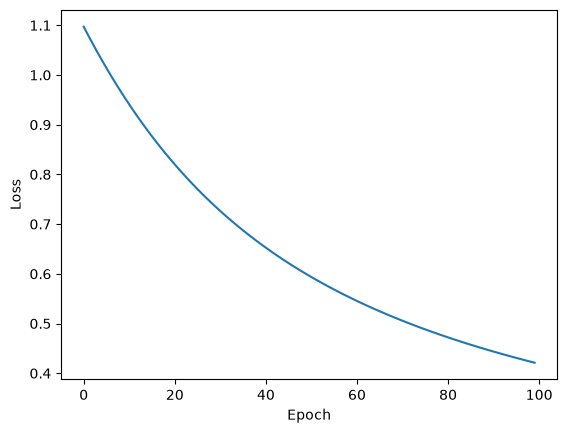

In [31]:
from matplotlib import pyplot as plt

plt.plot(history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [32]:
test_probs = linear.forward(X_test)
test_y = softmax(test_probs)
test_loss = softmax_cross_entropy.forward(test_probs, y_test.values)

print(f'Test loss: {test_loss}')
print(f'{test_y[2]}, {y_test.values[2]}')

Test loss: 0.3900843231714765
[0.10343887 0.20268455 0.69387658], [2]


In [33]:
from sklearn.metrics import accuracy_score

y_pred = np.argmax(test_y, axis=1)
y_true = y_test.values

accuracy_score(y_true, y_pred)

0.9722222222222222

***Готовые модели***

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

model = LogisticRegression()
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(model, param_grid, cv=5)
grid_search.fit(X_train, y_train.values.ravel())

test_y = grid_search.predict(X_test)

accuracy_score(y_true, test_y)

1.0

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim

In [36]:
class WineClassifier(nn.Module):
    def __init__(self, input_size, output_size):
        super(WineClassifier, self).__init__()
        self.linear1 = nn.Linear(input_size, 64)
        self.linear2 = nn.Linear(64, output_size)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.linear1(x))
        x = self.linear2(x)
        return x

In [37]:
model = WineClassifier(X.shape[1], 3)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [46]:
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train.values.ravel(), dtype=torch.long)

In [47]:
epoches = 100

model.train()

for epoch in range(epoches):
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    print(f'Epoch: {epoch}, Loss: {loss}')

Epoch: 0, Loss: 1.0068386793136597
Epoch: 1, Loss: 0.9892568588256836
Epoch: 2, Loss: 0.9719365239143372
Epoch: 3, Loss: 0.9548702239990234
Epoch: 4, Loss: 0.9380479454994202
Epoch: 5, Loss: 0.9214909672737122
Epoch: 6, Loss: 0.9051802754402161
Epoch: 7, Loss: 0.8890883922576904
Epoch: 8, Loss: 0.8732267022132874
Epoch: 9, Loss: 0.8575657606124878
Epoch: 10, Loss: 0.8421216011047363
Epoch: 11, Loss: 0.8268781304359436
Epoch: 12, Loss: 0.811860978603363
Epoch: 13, Loss: 0.7970437407493591
Epoch: 14, Loss: 0.7824437022209167
Epoch: 15, Loss: 0.7680366039276123
Epoch: 16, Loss: 0.7538019418716431
Epoch: 17, Loss: 0.7397444248199463
Epoch: 18, Loss: 0.7258278727531433
Epoch: 19, Loss: 0.7120694518089294
Epoch: 20, Loss: 0.6984719038009644
Epoch: 21, Loss: 0.6850468516349792
Epoch: 22, Loss: 0.6717802882194519
Epoch: 23, Loss: 0.6586651802062988
Epoch: 24, Loss: 0.6457129120826721
Epoch: 25, Loss: 0.6329070329666138
Epoch: 26, Loss: 0.6202380061149597
Epoch: 27, Loss: 0.6077163815498352
Epo